# **Freight rate prediction**

clean the data, build features, validate with time-based folds, compare models, train the final model, predict the 12,000 validation loads, and run `score.py`.

**To run:** put the input files in `data/` (`train_test.csv`, `validation.csv`, `december_chart_inputs.csv`) and keep `score.py` and `requirements.txt` next to this notebook, then choose *Run all* (about 90 seconds).

This notebook contains different parts:


1.   Part 1: Load and clean the data, flag price outliers
2.   Part 2: Features, December chart file, time-based folds, baseline


1.   Part 3: Train and compare models, error analysis
2.   Part 4: Final model, predictions, `score.py`







In [6]:
#versions checking
import matplotlib
import numpy
import pandas

print("matplotlib:", matplotlib.__version__)
print("numpy:     ", numpy.__version__)
print("pandas:    ", pandas.__version__)

matplotlib: 3.10.0
numpy:      2.1.3
pandas:     2.2.3


In [7]:
#downloading requirements
!pip install -r requirements.txt

In [8]:
import pandas as pd
import numpy as np

In [9]:
TRAIN_PATH = "/content/data/train-test.csv"
VAL_PATH = "/content/data/validation.csv"

In [12]:
#parse date to handle the date maths later/ ensure correct chronological handling
train = pd.read_csv(TRAIN_PATH, parse_dates=["date"])
val   = pd.read_csv(VAL_PATH,   parse_dates=["date"])

print("train shape:", train.shape, "(rows, columns)")
print("val shape:  ", val.shape)
train.head()

train shape: (48000, 14) (rows, columns)
val shape:   (12000, 13)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


# **Part 1: Load and Clean **

check data quality before cleaning
Measure the problems before solving them

In [13]:
#check data quality before cleaning
print("Date range  train:", train["date"].min().date(), "->", train["date"].max().date())
print("Date range  val:  ", val["date"].min().date(),   "->", val["date"].max().date())

print("\nMissing values in train:")
print(train.isna().sum()[train.isna().sum() > 0])

print("\nMissing values in val:")
print(val.isna().sum()[val.isna().sum() > 0])

print("\nNegative weights   train:", (train["weight"] < 0).sum(), "  val:", (val["weight"] < 0).sum())
print("Duplicate load_ids train:", train["load_id"].duplicated().sum(), "  val:", val["load_id"].duplicated().sum())

Date range  train: 2025-01-01 -> 2025-10-31
Date range  val:   2025-11-01 -> 2025-12-31

Missing values in train:
weight          300
market_index    374
dtype: int64

Missing values in val:
weight          165
market_index    249
dtype: int64

Negative weights   train: 292   val: 145
Duplicate load_ids train: 0   val: 0


Fix Weight and Market index

Negative weights are flipped to positive. Missing values are filled with medians (computed from train only and reused on validation), and a 0/1 flag records which rows were filled.

In [14]:
def clean_features(df, weight_median_by_equipment, overall_market_median):
    """Fix weight and market_index. Returns a cleaned COPY (the original stays untouched)."""
    df = df.copy()

    # weight
    df["weight"] = df["weight"].abs()                                   # -47500 -> 47500
    df["weight_was_missing"] = df["weight"].isna().astype(int)          # 1 if missing, else 0
    fill_values = df["equipment"].map(weight_median_by_equipment)       # typical weight for each row's equipment
    df["weight"] = df["weight"].fillna(fill_values)

    # market_index
    df["market_index_was_missing"] = df["market_index"].isna().astype(int)
    same_day_median = df.groupby("date")["market_index"].transform("median")   # median of that row's date
    df["market_index"] = df["market_index"].fillna(same_day_median)
    df["market_index"] = df["market_index"].fillna(overall_market_median)      # safety net

    return df


# Work out the "typical values" from TRAIN only, then reuse them for validation.
# (Habit: learn everything from train, apply it to everything else.)
weight_medians = train["weight"].abs().groupby(train["equipment"]).median()
market_median  = train["market_index"].median()
print("Typical weight by equipment:\n", weight_medians.round(0))

train = clean_features(train, weight_medians, market_median)
val   = clean_features(val,   weight_medians, market_median)

Typical weight by equipment:
 equipment
Dry Van    31444.0
Flatbed    31532.0
Reefer     31577.0
Name: weight, dtype: float64


Flag Price outliers (TRAIN ONLY)

A simple expected-price formula (log distance + equipment) gives every load a robust score. Loads with |score| > 5 are flagged. They are **flagged, not deleted**: later they are left out of training only, and kept in every test fold.

In [15]:
def add_outlier_flag(df, threshold=5):
    """Adds `outlier_z` and `is_outlier` columns. Needs the real price, so TRAIN only."""
    df = df.copy()

    # Simple model: log(price) = a + b*log(distance) + (reefer bump) + (flatbed bump)
    X = np.column_stack([
        np.ones(len(df)),                      # the constant "a"
        np.log(df["distance"]),                # distance effect
        (df["equipment"] == "Reefer"),         # 1 if reefer else 0
        (df["equipment"] == "Flatbed"),        # 1 if flatbed else 0
    ]).astype(float)
    y = np.log(df["posted_rate"])

    coef = np.linalg.lstsq(X, y, rcond=None)[0]       # find the best-fitting numbers
    error = y - X @ coef                              # real minus expected (log scale)

    middle = np.median(error)
    spread = np.median(np.abs(error - middle)) * 1.4826   # "robust standard deviation"
    df["outlier_z"] = (error - middle) / spread
    df["is_outlier"] = (df["outlier_z"].abs() > threshold).astype(int)
    return df


train = add_outlier_flag(train)

print("Outliers found:", train["is_outlier"].sum(), "of", len(train),
      f"({train['is_outlier'].mean():.1%})")
print("  too expensive:", (train["outlier_z"] > 5).sum(), "  too cheap:", (train["outlier_z"] < -5).sum())

Outliers found: 677 of 48000 (1.4%)
  too expensive: 340   too cheap: 337


In [16]:
bins   = [-100, -8, -6, -5, -4, -3, 3, 4, 5, 6, 8, 100]
counts = pd.cut(train["outlier_z"], bins=bins).value_counts().sort_index()
print(counts)

outlier_z
(-100, -8]      337
(-8, -6]          0
(-6, -5]          0
(-5, -4]          0
(-4, -3]         40
(-3, 3]       47267
(3, 4]           15
(4, 5]            1
(5, 6]            0
(6, 8]            0
(8, 100]        340
Name: count, dtype: int64


In [17]:
print(train.groupby(train["date"].dt.to_period("M"))["is_outlier"].agg(["sum", "mean"]).round(3))

print("\nExamples of flagged rows:")
cols = ["pickup", "delivery", "distance", "equipment", "posted_rate", "outlier_z"]
train.loc[train["is_outlier"] == 1, cols].head(8)

         sum   mean
date               
2025-01   81  0.016
2025-02   57  0.013
2025-03   71  0.014
2025-04   66  0.014
2025-05   62  0.013
2025-06   63  0.013
2025-07   65  0.013
2025-08   68  0.014
2025-09   64  0.014
2025-10   80  0.016

Examples of flagged rows:


,pickup,delivery,distance,equipment,posted_rate,outlier_z
50,Los Angeles,Green Bay,2202.5,Reefer,1243.45,-24.653881
190,Tampa,Milwaukee,919.8,Dry Van,704.89,-18.778752
294,Greensboro,Syracuse,685.6,Dry Van,518.31,-19.749927
388,Corpus Christi,Chattanooga,823.0,Flatbed,5485.49,20.282989
439,Richmond,Charleston,394.9,Dry Van,276.27,-22.554403
469,Phoenix,Jacksonville,2154.3,Dry Van,10854.69,18.836168
508,Las Vegas,Grand Rapids,1976.4,Flatbed,699.41,-32.998342
785,Kansas City,Charleston,861.5,Dry Van,4587.83,17.652951


Safety check + save

`assert` lines stop the notebook if the cleaning did not work.

In [18]:
for name, df in [("train", train), ("val", val)]:
    assert df["weight"].isna().sum() == 0,        f"{name}: weight still has missing values"
    assert df["market_index"].isna().sum() == 0,  f"{name}: market_index still has missing values"
    assert (df["weight"] > 0).all(),              f"{name}: weight still has zero/negative values"
    assert df["load_id"].is_unique,               f"{name}: duplicate load_ids"

assert len(val) == 12000, "validation should have 12,000 rows"
print("All checks passed.")

All checks passed.


In [19]:
import os
os.makedirs("data", exist_ok=True)
train.to_csv("data/train_clean.csv", index=False)
val.to_csv("data/validation_clean.csv", index=False)
print("Saved data/train_clean.csv and data/validation_clean.csv")

Saved data/train_clean.csv and data/validation_clean.csv


# **Part 2: Features, December file and time-based split:**

Reload the cleaned files and the December chart file.

In [21]:
import pandas as pd
import numpy as np

train = pd.read_csv("data/train_clean.csv",      parse_dates=["date"])
val   = pd.read_csv("data/validation_clean.csv", parse_dates=["date"])
chart = pd.read_csv("/content/data/december-chart-inputs.csv", parse_dates=["date"])

print(train.shape, val.shape, chart.shape)

(48000, 18) (12000, 15) (31, 7)


Build the features

Distance (raw and log), equipment flags, weight, coordinates and trip direction, and the market signals (each load's own value and the daily median). City names and month are left out on purpose: 8 validation cities never appear in train, and months 11 and 12 are not in train.

In [22]:
def daily_signal_table(df):
    """One row per date: the median market_index and median quote_signal of all loads that day."""
    table = df.groupby("date")[["market_index", "quote_signal"]].median()
    return table.rename(columns={"market_index": "market_index_day",
                                 "quote_signal": "quote_signal_day"})


def make_features(df, daily_table):
    """Return a copy of df with all model features added."""
    out = df.copy()

    # market signals for that date
    out["market_index_day"] = out["date"].map(daily_table["market_index_day"])
    out["quote_signal_day"] = out["date"].map(daily_table["quote_signal_day"])

    # distance
    out["log_distance"] = np.log(out["distance"])   # price grows slower than distance, log captures that

    # equipment -> numbers (Dry Van is the "default" when both are 0)
    out["is_reefer"]  = (out["equipment"] == "Reefer").astype(int)
    out["is_flatbed"] = (out["equipment"] == "Flatbed").astype(int)

    # direction of the trip
    out["delta_lat"] = out["delivery_lat"] - out["pickup_lat"]   # + = going north
    out["delta_lon"] = out["delivery_lon"] - out["pickup_lon"]   # + = going east

    return out


FEATURES = [
    "distance", "log_distance", "weight", "weight_was_missing",
    "is_reefer", "is_flatbed",
    "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "delta_lat", "delta_lon",
    "market_index", "quote_signal",            # the load's own values
    "market_index_day", "quote_signal_day",    # the daily medians
]

# Each file gets its signals from ITS OWN dates (no price is involved, so nothing leaks)
train_f = make_features(train, daily_signal_table(train))
val_daily = daily_signal_table(val)
val_f   = make_features(val, val_daily)

print("Missing values in train features:", int(train_f[FEATURES].isna().sum().sum()))
print("Missing values in val features:  ", int(val_f[FEATURES].isna().sum().sum()))
train_f[FEATURES].head()

Missing values in train features: 0
Missing values in val features:   0


,distance,log_distance,weight,weight_was_missing,is_reefer,is_flatbed,pickup_lat,pickup_lon,delivery_lat,delivery_lon,delta_lat,delta_lon,market_index,quote_signal,market_index_day,quote_signal_day
0,274.3,5.614222,30658.0,0,0,0,38.09122,-76.78906,38.16908,-72.74564,0.07786,4.04342,0.95684,2.39595,0.96259,2.01772
1,280.5,5.636574,17555.0,0,1,0,38.09122,-76.78906,39.22317,-72.96710,1.13195,3.82196,0.97623,2.43355,0.96259,2.01772
2,967.8,6.875025,31721.0,0,0,0,39.22317,-72.96710,44.30296,-87.52871,5.07979,-14.56161,1.00971,1.84491,0.96259,2.01772
3,965.4,6.872543,32333.0,0,0,0,39.55328,-72.18051,34.84933,-86.28940,-4.70395,-14.10889,0.94518,1.87712,0.96259,2.01772
4,541.9,6.295081,35183.0,0,1,0,31.83025,-94.38343,35.29479,-88.08915,3.46454,6.29428,0.98480,2.56300,0.96259,2.01772


Prepare the December chart

One fixed load repeated for 31 days. Coordinates come from a city lookup. The market signals use each date's median from `validation.csv`, so the model answers: what would a typical load on this date cost?

In [23]:
# city -> (lat, lon) lookup
pick = pd.concat([train[["pickup", "pickup_lat", "pickup_lon"]],   val[["pickup", "pickup_lat", "pickup_lon"]]])
drop = pd.concat([train[["delivery", "delivery_lat", "delivery_lon"]], val[["delivery", "delivery_lat", "delivery_lon"]]])
pick.columns = drop.columns = ["city", "lat", "lon"]
coords = pd.concat([pick, drop]).drop_duplicates()

# sanity check: each city should have exactly ONE coordinate pair
assert coords["city"].is_unique, "a city has two different coordinates!"
coords = coords.set_index("city")

chart["pickup_lat"]   = chart["pickup"].map(coords["lat"])
chart["pickup_lon"]   = chart["pickup"].map(coords["lon"])
chart["delivery_lat"] = chart["delivery"].map(coords["lat"])
chart["delivery_lon"] = chart["delivery"].map(coords["lon"])
chart["weight_was_missing"] = 0

# No per-load market signals in this file -> use a "typical load" for each date (the daily median)
chart["market_index"] = chart["date"].map(val_daily["market_index_day"])
chart["quote_signal"] = chart["date"].map(val_daily["quote_signal_day"])

chart_f = make_features(chart, val_daily)     # signals for December come from validation.csv

assert chart_f[FEATURES].isna().sum().sum() == 0, "December rows still have missing features"
print("December chart rows ready:", len(chart_f))
chart_f[["date", "market_index_day", "quote_signal_day"]].head()

December chart rows ready: 31


,date,market_index_day,quote_signal_day
0,2025-12-01,0.833480,2.05861
1,2025-12-02,0.914660,2.04049
2,2025-12-03,0.994420,2.03694
3,2025-12-04,1.025015,2.06670
4,2025-12-05,0.974900,2.06752


TIME based folds

Validation is the future, so every fold trains on the past and tests on the next two months. Outliers are removed from the training part only. The `assert` checks that every test date is later than every training date.

In [24]:
train_f["month"] = train_f["date"].dt.month

FOLDS = [
    {"name": "Fold 1", "train_months": [1, 2, 3, 4],             "test_months": [5, 6]},
    {"name": "Fold 2", "train_months": [1, 2, 3, 4, 5, 6],       "test_months": [7, 8]},
    {"name": "Fold 3", "train_months": [1, 2, 3, 4, 5, 6, 7, 8], "test_months": [9, 10]},
]

def get_fold(df, fold):
    """Return (train_part, test_part) for one fold."""
    train_part = df[df["month"].isin(fold["train_months"]) & (df["is_outlier"] == 0)]
    test_part  = df[df["month"].isin(fold["test_months"])]
    return train_part, test_part


# Check: every test row must come AFTER every train row (no peeking at the future)
rows = []
for fold in FOLDS:
    tr_part, te_part = get_fold(train_f, fold)
    assert tr_part["date"].max() < te_part["date"].min(), "train and test overlap in time!"
    rows.append({"fold": fold["name"],
                 "train rows": len(tr_part), "train until": tr_part["date"].max().date(),
                 "test rows": len(te_part),  "test from": te_part["date"].min().date(),
                 "outliers in test": int(te_part["is_outlier"].sum())})
pd.DataFrame(rows)

,fold,train rows,train until,test rows,test from,outliers in test
0,Fold 1,18835,2025-04-30,9696,2025-05-01,125
1,Fold 2,28406,2025-06-30,9671,2025-07-01,133
2,Fold 3,37944,2025-08-31,9523,2025-09-01,144


Baseline

Distance times the typical price per mile for the equipment type. Every model has to beat this.

In [25]:
def score(y_true, y_pred):
    err = np.abs(y_pred - y_true)
    return {"MAE ($)": err.mean(),
            "MAPE (%)": (err / y_true).mean() * 100,
            "MedianAPE (%)": np.median(err / y_true) * 100}


def baseline_predict(train_part, test_part):
    price_per_mile = (train_part["posted_rate"] / train_part["distance"]).groupby(train_part["equipment"]).median()
    return test_part["distance"] * test_part["equipment"].map(price_per_mile)


results = []
for fold in FOLDS:
    tr_part, te_part = get_fold(train_f, fold)
    pred = pd.Series(baseline_predict(tr_part, te_part), index=te_part.index)
    clean = te_part["is_outlier"] == 0

    all_rows   = score(te_part["posted_rate"], pred)
    clean_rows = score(te_part.loc[clean, "posted_rate"], pred[clean])
    results.append({"fold": fold["name"],
                    **{f"{k} all": v for k, v in all_rows.items()},
                    **{f"{k} clean": v for k, v in clean_rows.items()}})

results = pd.DataFrame(results).set_index("fold")
results.loc["average"] = results.mean()
results.round(2).T

fold,Fold 1,Fold 2,Fold 3,average
MAE ($) all,206.15,222.81,229.08,219.35
MAPE (%) all,11.01,10.11,10.49,10.53
MedianAPE (%) all,7.05,6.71,6.80,6.85
MAE ($) clean,153.72,172.41,175.09,167.07
MAPE (%) clean,8.93,7.96,8.09,8.33
MedianAPE (%) clean,6.95,6.59,6.67,6.74


Save the features tables

In [26]:
keep_train = ["load_id", "date", "month", "pickup", "delivery", "equipment", "posted_rate", "is_outlier"] + FEATURES
keep_val   = ["load_id", "date", "pickup", "delivery", "equipment"] + FEATURES
keep_chart = ["date", "pickup", "delivery", "equipment"] + FEATURES

train_f[keep_train].to_csv("data/train_features.csv", index=False)
val_f[keep_val].to_csv("data/val_features.csv", index=False)
chart_f[keep_chart].to_csv("data/december_chart_features.csv", index=False)

with open("data/feature_list.txt", "w") as f:
    f.write("\n".join(FEATURES))

print("Saved train_features.csv, val_features.csv, december_chart_features.csv, feature_list.txt")

Saved train_features.csv, val_features.csv, december_chart_features.csv, feature_list.txt


# **Part 3: Train and compare models **



In [27]:
# If you get "No module named lightgbm", run this line once:  !pip install lightgbm
import json
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

train = pd.read_csv("data/train_features.csv", parse_dates=["date"])
FEATURES = open("data/feature_list.txt").read().split()

print("Rows:", len(train), "| Features:", len(FEATURES))
print(FEATURES)

Rows: 48000 | Features: 16
['distance', 'log_distance', 'weight', 'weight_was_missing', 'is_reefer', 'is_flatbed', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'delta_lat', 'delta_lon', 'market_index', 'quote_signal', 'market_index_day', 'quote_signal_day']


In [28]:
FOLDS = [
    {"name": "Fold 1", "train_months": [1, 2, 3, 4],             "test_months": [5, 6]},
    {"name": "Fold 2", "train_months": [1, 2, 3, 4, 5, 6],       "test_months": [7, 8]},
    {"name": "Fold 3", "train_months": [1, 2, 3, 4, 5, 6, 7, 8], "test_months": [9, 10]},
]

def get_fold(df, fold):
    train_part = df[df["month"].isin(fold["train_months"]) & (df["is_outlier"] == 0)]
    test_part  = df[df["month"].isin(fold["test_months"])]
    return train_part, test_part

def score(y_true, y_pred):
    err = np.abs(y_pred - y_true)
    return {"MAE ($)": err.mean(),
            "MAPE (%)": (err / y_true).mean() * 100,
            "MedianAPE (%)": np.median(err / y_true) * 100}

The 3 Models

**A.** the baseline, **B.** linear regression on log(price), **C.** LightGBM on log(price). Predicting the log makes a 5% miss count the same on cheap and expensive loads; predictions are converted back with `exp()`.

In [29]:
def predict_baseline(train_part, test_part):
    price_per_mile = (train_part["posted_rate"] / train_part["distance"]).groupby(train_part["equipment"]).median()
    return test_part["distance"] * test_part["equipment"].map(price_per_mile)


LINEAR_FEATURES = ["log_distance", "is_reefer", "is_flatbed", "weight",
                   "market_index", "quote_signal", "market_index_day", "quote_signal_day"]

def predict_linear(train_part, test_part):
    model = LinearRegression().fit(train_part[LINEAR_FEATURES], np.log(train_part["posted_rate"]))
    return pd.Series(np.exp(model.predict(test_part[LINEAR_FEATURES])), index=test_part.index)


LGBM_PARAMS = dict(
    n_estimators=600,        # number of trees
    learning_rate=0.03,      # how big a step each tree takes (small = careful)
    num_leaves=31,           # how complex each tree can be
    min_child_samples=40,    # a leaf needs at least 40 loads (stops memorizing single loads)
    subsample=0.8, subsample_freq=1,   # each tree sees a random 80% of the rows
    colsample_bytree=0.8,              # ... and a random 80% of the features
    random_state=42,         # fixed seed = same result every run
    verbose=-1,
)

def predict_lgbm(train_part, test_part, params=LGBM_PARAMS, features=FEATURES):
    model = lgb.LGBMRegressor(**params)
    model.fit(train_part[features], np.log(train_part["posted_rate"]))
    return pd.Series(np.exp(model.predict(test_part[features])), index=test_part.index)

Cross validate on all models on the same folds

Scores are reported on all test rows and on clean rows (outliers removed).

In [30]:
def cross_validate(predict_fn, df=train, **kwargs):
    fold_scores, oof_parts = [], []
    for fold in FOLDS:
        train_part, test_part = get_fold(df, fold)
        pred = predict_fn(train_part, test_part, **kwargs)
        clean = (test_part["is_outlier"] == 0).values

        all_rows   = score(test_part["posted_rate"].values, pred.values)
        clean_rows = score(test_part["posted_rate"].values[clean], pred.values[clean])
        fold_scores.append({"fold": fold["name"],
                            **{f"{k} all": v for k, v in all_rows.items()},
                            **{f"{k} clean": v for k, v in clean_rows.items()}})
        oof_parts.append(test_part.assign(pred=pred))
    return pd.DataFrame(fold_scores).set_index("fold"), pd.concat(oof_parts)


models = {"A. Baseline": predict_baseline, "B. Linear (log)": predict_linear, "C. LightGBM (log)": predict_lgbm}

fold_tables, oof = {}, {}
for name, fn in models.items():
    fold_tables[name], oof[name] = cross_validate(fn)

summary = pd.DataFrame({name: table.mean() for name, table in fold_tables.items()}).T
summary.round(2)

,MAE ($) all,MAPE (%) all,MedianAPE (%) all,MAE ($) clean,MAPE (%) clean,MedianAPE (%) clean
A. Baseline,219.35,10.53,6.85,167.07,8.33,6.74
B. Linear (log),135.52,5.88,3.30,82.01,3.59,3.26
C. LightGBM (log),111.36,4.84,2.07,57.67,2.54,2.03


In [31]:
# Average % error (all rows), fold by fold, for every model
pd.DataFrame({name: table["MAPE (%) all"] for name, table in fold_tables.items()}).round(2)

,A. Baseline,B. Linear (log),C. LightGBM (log)
fold,,,
Fold 1,11.01,5.12,3.98
Fold 2,10.11,5.48,5.13
Fold 3,10.49,7.03,5.42


In [32]:
fold_tables["C. LightGBM (log)"].round(2)

,MAE ($) all,MAPE (%) all,MedianAPE (%) all,MAE ($) clean,MAPE (%) clean,MedianAPE (%) clean
fold,,,,,,
Fold 1,94.82,3.98,1.37,41.08,1.72,1.35
Fold 2,114.35,5.13,2.10,62.62,2.93,2.06
Fold 3,124.91,5.42,2.73,69.30,2.98,2.68


Test Robustness: 3 lightGBM settings

If the score barely moves, the result is stable and heavy tuning is not worth it.

In [33]:
configs = {
    "default (31 leaves)":   LGBM_PARAMS,
    "smaller (15 leaves)":   {**LGBM_PARAMS, "n_estimators": 1200, "learning_rate": 0.02, "num_leaves": 15},
    "bigger (63 leaves)":    {**LGBM_PARAMS, "n_estimators": 400, "num_leaves": 63},
}
rows = {}
for name, params in configs.items():
    table, _ = cross_validate(predict_lgbm, params=params)
    rows[name] = table.mean()
pd.DataFrame(rows).T.round(2)

,MAE ($) all,MAPE (%) all,MedianAPE (%) all,MAE ($) clean,MAPE (%) clean,MedianAPE (%) clean
default (31 leaves),111.36,4.84,2.07,57.67,2.54,2.03
smaller (15 leaves),111.54,4.85,2.17,57.81,2.55,2.14
bigger (63 leaves),111.38,4.84,1.99,57.69,2.54,1.95


Random splits vs TIME-bases splits

The same model with a shuffled split looks much better, only because it sees neighbouring days. The time-based number is the honest one.

In [34]:
random_scores = []
for fit_idx, test_idx in KFold(n_splits=5, shuffle=True, random_state=0).split(train):
    fit_part  = train.iloc[fit_idx]
    fit_part  = fit_part[fit_part["is_outlier"] == 0]
    test_part = train.iloc[test_idx]
    pred = predict_lgbm(fit_part, test_part)
    random_scores.append(score(test_part["posted_rate"].values, pred.values))

random_result = pd.DataFrame(random_scores).mean()
time_result   = fold_tables["C. LightGBM (log)"][["MAE ($) all", "MAPE (%) all", "MedianAPE (%) all"]].mean()
time_result.index = random_result.index

pd.DataFrame({"Random split (misleading)": random_result, "Time-based split (honest)": time_result}).round(2)

,Random split (misleading),Time-based split (honest)
MAE ($),82.26,111.36
MAPE (%),3.81,4.84
MedianAPE (%),1.16,2.07


Where is the model Wrong?

In [35]:
best = oof["C. LightGBM (log)"].copy()
best["abs_err"] = (best["pred"] - best["posted_rate"]).abs()
best["pct_err"] = best["abs_err"] / best["posted_rate"] * 100

out_rows  = best["is_outlier"] == 1
print(f"Outliers are {out_rows.mean():.1%} of rows but cause {best.loc[out_rows, 'abs_err'].sum() / best['abs_err'].sum():.0%} of all dollar error.")
print("No model can predict those, so they are the main reason the 'all' scores are worse than the 'clean' ones.")

Outliers are 1.4% of rows but cause 49% of all dollar error.
No model can predict those, so they are the main reason the 'all' scores are worse than the 'clean' ones.


In [36]:
clean = best[best["is_outlier"] == 0].copy()

def summarize(group):
    return group.agg(rows=("pct_err", "size"),
                     MAPE=("pct_err", "mean"),
                     MedianAPE=("pct_err", "median"),
                     MAE=("abs_err", "mean")).round(2)

print("By equipment type:")
display(summarize(clean.groupby("equipment")))

clean["distance band (mi)"] = pd.cut(clean["distance"], [0, 200, 400, 800, 1500, 2500, 4000])
print("By distance:")
display(summarize(clean.groupby("distance band (mi)", observed=True)))

By equipment type:


,rows,MAPE,MedianAPE,MAE
equipment,,,,
Dry Van,16155,2.30,1.82,48.52
Flatbed,5186,2.71,2.05,64.11
Reefer,7147,2.95,2.23,73.33


By distance:


,rows,MAPE,MedianAPE,MAE
distance band (mi),,,,
"(0, 200]",1045,4.27,3.34,16.82
"(200, 400]",3129,2.68,1.93,21.10
"(400, 800]",7465,2.58,1.88,35.82
"(800, 1500]",8762,2.51,2.04,59.02
"(1500, 2500]",6500,2.24,1.84,88.82
"(2500, 4000]",1587,2.25,1.74,122.85


In [37]:
# By month: also check "bias" = are we systematically too low (negative) or too high (positive)?
by_month = clean.groupby("month").apply(lambda g: pd.Series({
    "MAPE (%)": g["pct_err"].mean(),
    "bias (%)": (g["pred"] / g["posted_rate"]).mean() * 100 - 100,
})).round(2)
by_month

/tmp/ipykernel_2544/2254273662.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_month = clean.groupby("month").apply(lambda g: pd.Series({


,MAPE (%),bias (%)
month,,
5,1.41,-0.57
6,2.03,-1.45
7,1.74,-1.09
8,4.16,-2.53
9,2.06,-1.67
10,3.87,-3.76


Feature Importance

Importance scores are dominated by distance. Removing whole feature groups shows the others still matter.

In [38]:
fit_part, _ = get_fold(train, FOLDS[-1])
final_check = lgb.LGBMRegressor(**LGBM_PARAMS).fit(fit_part[FEATURES], np.log(fit_part["posted_rate"]))

importance = pd.Series(final_check.booster_.feature_importance(importance_type="gain"), index=FEATURES)
(importance / importance.sum() * 100).sort_values(ascending=False).round(1)

,0
distance,69.7
log_distance,28.9
is_reefer,0.4
quote_signal,0.3
is_flatbed,0.1
weight,0.1
market_index_day,0.1
delta_lon,0.1
market_index,0.1
quote_signal_day,0.0


In [39]:
groups = {
    "all features":           FEATURES,
    "without geography":      [f for f in FEATURES if "lat" not in f and "lon" not in f],
    "without market signals": [f for f in FEATURES if "market_index" not in f and "quote_signal" not in f],
    "without weight":         [f for f in FEATURES if "weight" not in f],
}
ablation = {}
for name, feats in groups.items():
    table, _ = cross_validate(predict_lgbm, features=feats)
    ablation[name] = table.mean()
pd.DataFrame(ablation).T[["MAE ($) all", "MAPE (%) all", "MedianAPE (%) all"]].round(2)

,MAE ($) all,MAPE (%) all,MedianAPE (%) all
all features,111.36,4.84,2.07
without geography,121.26,5.32,2.03
without market signals,134.58,5.64,3.09
without weight,117.69,5.18,2.11


Chart Save and Results

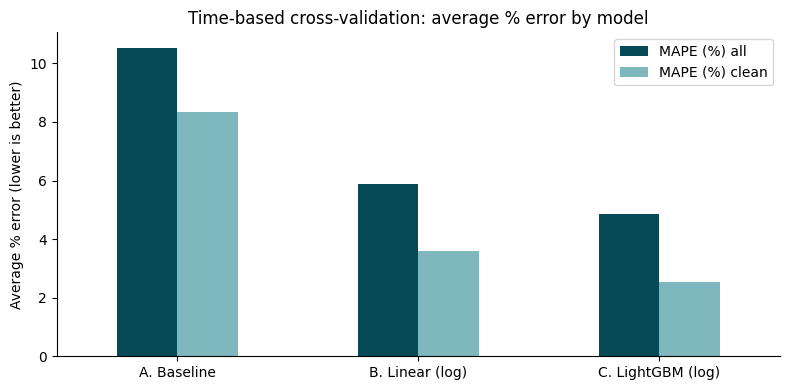

Saved model_comparison.png, cv_results_summary.csv, cv_results_lgbm_by_fold.csv, final_params.json


In [40]:
plot_data = summary[["MAPE (%) all", "MAPE (%) clean"]]
ax = plot_data.plot(kind="bar", figsize=(8, 4), color=["#064A56", "#7FB7BE"], rot=0)
ax.set_ylabel("Average % error (lower is better)")
ax.set_title("Time-based cross-validation: average % error by model")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

summary.round(3).to_csv("data/cv_results_summary.csv")
fold_tables["C. LightGBM (log)"].round(3).to_csv("data/cv_results_lgbm_by_fold.csv")
with open("data/final_params.json", "w") as f:
    json.dump(LGBM_PARAMS, f, indent=2)
print("Saved model_comparison.png, cv_results_summary.csv, cv_results_lgbm_by_fold.csv, final_params.json")

# **Part 4: Final Model and Predictions **



In [41]:
import json
import os
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

train      = pd.read_csv("data/train_features.csv", parse_dates=["date"])
val        = pd.read_csv("data/val_features.csv", parse_dates=["date"])
chart_feat = pd.read_csv("data/december_chart_features.csv", parse_dates=["date"])
chart_orig = pd.read_csv("/content/data/december-chart-inputs.csv")      # the ORIGINAL file, we fill its predicted_rate column

FEATURES = open("data/feature_list.txt").read().split()
PARAMS   = json.load(open("data/final_params.json"))

print(len(train), "train rows |", len(val), "validation rows |", len(chart_feat), "December rows")

48000 train rows | 12000 validation rows | 31 December rows


Train on all labeled Data
Same model and settings, trained on every non-outlier row (January to October).

In [42]:
fit_rows = train[train["is_outlier"] == 0]
print("Training on", len(fit_rows), "rows (", int(train["is_outlier"].sum()), "outliers left out )")

final_model = lgb.LGBMRegressor(**PARAMS)
final_model.fit(fit_rows[FEATURES], np.log(fit_rows["posted_rate"]))
print("Model trained.")

Training on 47323 rows ( 677 outliers left out )
Model trained.


Does Validation look like train?
share the validation rows with a feature outside the range seen in training

In [43]:
outside = {}
for f in FEATURES:
    lo, hi = train[f].min(), train[f].max()
    outside[f] = ((val[f] < lo) | (val[f] > hi)).mean() * 100

outside = pd.Series(outside).round(2)
print("% of validation rows outside the training range (only features with any shown):")
print(outside[outside > 0])

% of validation rows outside the training range (only features with any shown):
pickup_lat      0.74
delivery_lat    0.88
delta_lat       0.18
dtype: float64


Predict the validation set and Save

`validation_predictions.csv` must contain exactly `load_id,predicted_rate`.

In [44]:
val_pred = np.exp(final_model.predict(val[FEATURES]))

submission = pd.DataFrame({"load_id": val["load_id"], "predicted_rate": val_pred.round(2)})
submission.to_csv("validation_predictions.csv", index=False)

# Our own checks (score.py will check again)
assert list(submission.columns) == ["load_id", "predicted_rate"]
assert len(submission) == 12000
assert submission["load_id"].is_unique
assert submission["predicted_rate"].notna().all() and (submission["predicted_rate"] > 0).all()

# If you have the official template file, make sure the IDs match it exactly
template_path = "data/validation_predictions_template.csv"
if os.path.exists(template_path):
    template = pd.read_csv(template_path)
    assert set(template["load_id"]) == set(submission["load_id"]), "IDs do not match the template!"
    print("IDs match the template file.")

print("Saved validation_predictions.csv")
submission.head()

Saved validation_predictions.csv


,load_id,predicted_rate
0,TE-000001,816.38
1,TE-000002,4857.49
2,TE-000003,5189.83
3,TE-000004,4038.89
4,TE-000005,1797.16


Sanity check

predicted price per mile by equipment should look like real training prices

In [45]:
check = val.assign(pred=val_pred)
check["pred_per_mile"] = check["pred"] / check["distance"]
train_ppm = (fit_rows["posted_rate"] / fit_rows["distance"]).groupby(fit_rows["equipment"]).mean()

pd.DataFrame({
    "train real $/mile":     train_ppm,
    "validation pred $/mile": check.groupby("equipment")["pred_per_mile"].mean(),
}).round(2)

,train real $/mile,validation pred $/mile
equipment,,
Dry Van,2.09,2.05
Flatbed,2.26,2.17
Reefer,2.36,2.27


In [46]:
# Average predicted price per week, to see if the predictions follow the market sensibly
weekly = check.groupby(check["date"].dt.to_period("W"))[["pred", "market_index_day"]].mean().round(2)
weekly

,pred,market_index_day
date,,
2025-10-27/2025-11-02,2336.49,0.87
2025-11-03/2025-11-09,2265.58,0.93
2025-11-10/2025-11-16,2321.57,0.92
2025-11-17/2025-11-23,2258.90,0.92
2025-11-24/2025-11-30,2333.05,0.92
2025-12-01/2025-12-07,2275.59,0.92
2025-12-08/2025-12-14,2270.99,0.93
2025-12-15/2025-12-21,2297.44,0.93
2025-12-22/2025-12-28,2332.24,0.95


December chart predictions

Fill `predicted_rate` in the original December file (same seven columns, same order).

In [47]:
dec_pred = np.exp(final_model.predict(chart_feat[FEATURES]))

# Make sure the rows line up with the original file (same dates, same order)
assert (pd.to_datetime(chart_orig["date"]).values == chart_feat["date"].values).all()

december = chart_orig.copy()
december["predicted_rate"] = dec_pred.round(2)
december.to_csv("december_predictions.csv", index=False)

print("Columns:", list(december.columns))
december[["date", "predicted_rate"]].assign(market_index_day=chart_feat["market_index_day"].round(3).values)

Columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


,date,predicted_rate,market_index_day
0,2025-12-01,794.69,0.833
1,2025-12-02,799.21,0.915
2,2025-12-03,800.98,0.994
3,2025-12-04,818.88,1.025
4,2025-12-05,807.05,0.975
5,2025-12-06,799.29,0.890
6,2025-12-07,788.68,0.829
7,2025-12-08,788.68,0.840
8,2025-12-09,800.23,0.916
9,2025-12-10,811.29,1.001


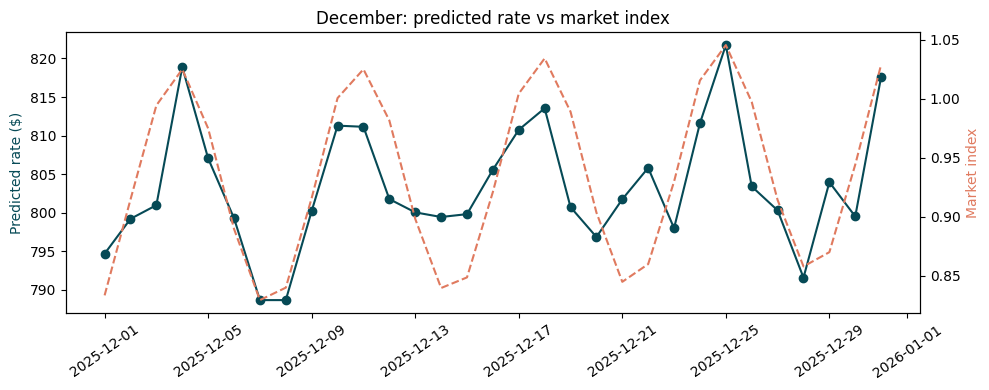

Correlation between the two: 0.798
Predicted rate range: $789 to $822


In [48]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(december["date"].astype("datetime64[ns]"), december["predicted_rate"], color="#064A56", marker="o", label="Predicted rate ($)")
ax1.set_ylabel("Predicted rate ($)", color="#064A56")
ax2 = ax1.twinx()
ax2.plot(chart_feat["date"], chart_feat["market_index_day"], color="#E07A5F", linestyle="--", label="Market index (daily)")
ax2.set_ylabel("Market index", color="#E07A5F")
ax1.tick_params(axis="x", rotation=35)
plt.title("December: predicted rate vs market index")
plt.tight_layout()
plt.show()

print("Correlation between the two:", round(np.corrcoef(december["predicted_rate"], chart_feat["market_index_day"])[0, 1], 3))
print("Predicted rate range: $%.0f to $%.0f" % (december["predicted_rate"].min(), december["predicted_rate"].max()))

Run the score.py

Validates both files and creates `scorer_results/candidate_december.png`.

In [49]:
!python score.py --predictions validation_predictions.csv --december-predictions december_predictions.csv

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


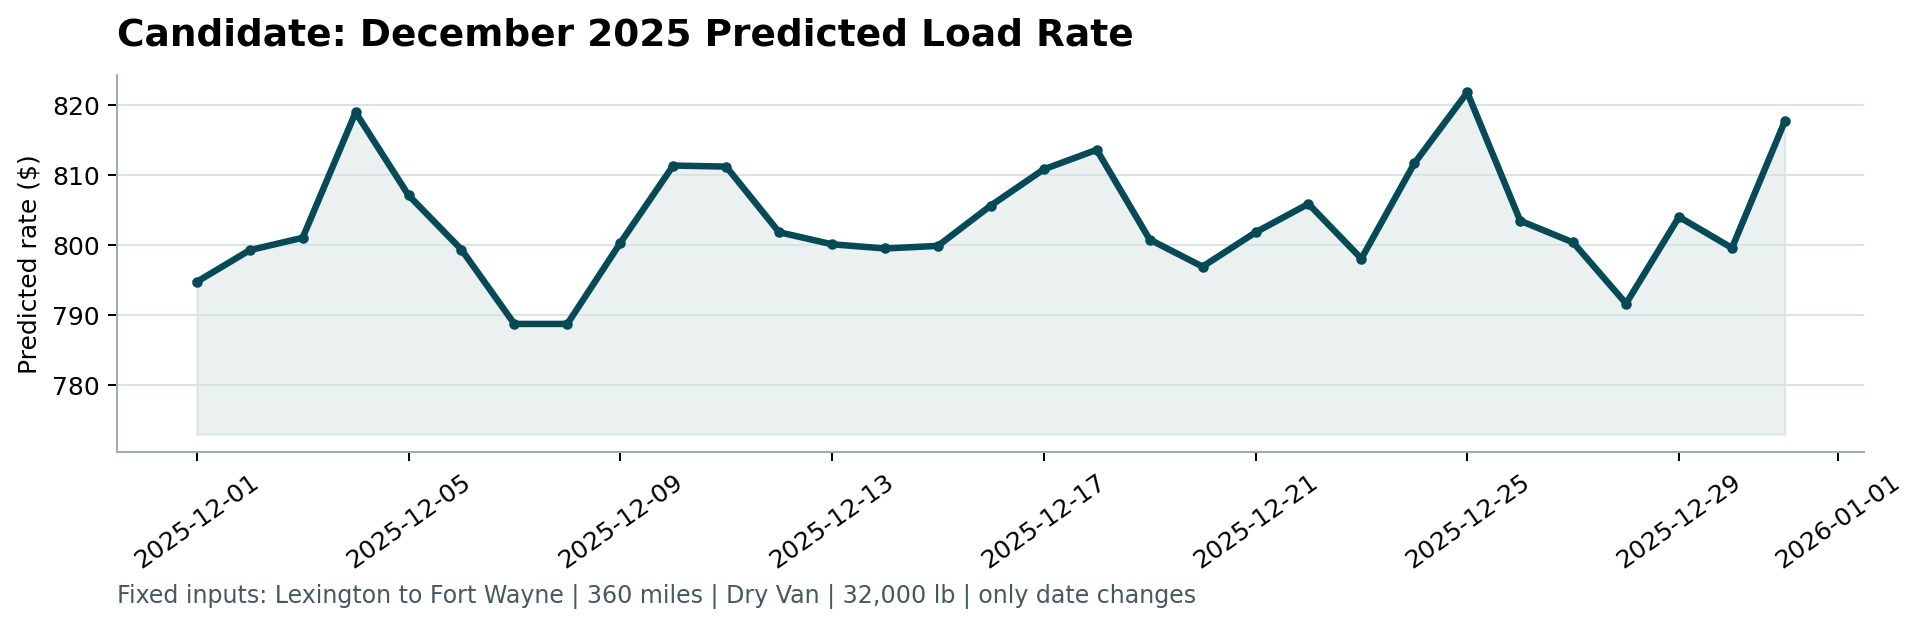

In [50]:
from IPython.display import Image
Image("scorer_results/candidate_december.png")